In [1]:
%load_ext autoreload
%autoreload 2

import numpy as np
import itertools

from smt.sampling_methods import LHS
from smt.surrogate_models import MixIntKernelType

from comcatalyst.context.cases import case_01, case_02, case_03
from comcatalyst.xprs.xpr_smt import XprSmt
from comcatalyst.xprs.visualizations import (
    plot_convergence, 
    plot_gp_quant_by_qual, 
    plot_3d_gp_quant_by_qual,
    plot_ground_truth,
    plot_3d_ground_truth
)

In [2]:
# context
case = case_01()

# hyperparameters
seed = 0
seed_ydoe_offset = 1000
n_init = 5
n_iter_bo = 10
n_start = 20
sampling_method = LHS
sampling_criterion = "ese"
kernel = MixIntKernelType.CONT_RELAX
bo_criterion = "EI"
sigma_noise = 0.1
qei="KBLB"

In [ ]:
# True max
x_true_max, y_true_max, X_grid, Y_grid = XprSmt.calc_true_max(
    fn_gp_objective=case.fn_gp_objective, 
    vars_metadata=case.vars_metadata, 
    z=case.z, 
    n_grid=1000
)

XprSmt.print_opt_result(x=x_true_max, y=y_true_max, vars_metadata=case.vars_metadata)

  x* = x_qual1 = A / x_qual2 = alpha / x_quant1 = 0.4935 / x_quant2 = 0.9980
  y* = 5.2992


In [5]:
# check répartition maxima
categ_combos = list(itertools.product(
    case.vars_metadata[0].support, # qual1
    case.vars_metadata[1].support, # qual2
))

for combo in categ_combos:
    mask = (
        (X_grid[:, 0] == case.vars_metadata[0].support.index(combo[0])) &
        (X_grid[:, 1] == case.vars_metadata[1].support.index(combo[1]))
    )
    y_combo = Y_grid[mask]
    combo_label = f"{combo[0]}/{combo[1]}"
    print(
        f"{combo_label:<8} :  "
        f"max ={y_combo.max():6.3f}   "
        f"min ={y_combo.min():7.3f}   "
        f"mean ={y_combo.mean():6.3f}   "
        f"% > 0.8*max ={100*(y_combo > 0.8*Y_grid.max()).mean():5.1f}%"
    )

A/alpha  :  max = 5.299   min = -5.779   mean =-0.004   % > 0.8*max =  5.5%
A/beta   :  max = 1.817   min = -9.088   mean =-1.336   % > 0.8*max =  0.0%
B/alpha  :  max = 4.884   min = -6.994   mean =-0.004   % > 0.8*max = 11.5%
B/beta   :  max = 0.045   min = -9.074   mean =-1.336   % > 0.8*max =  0.0%


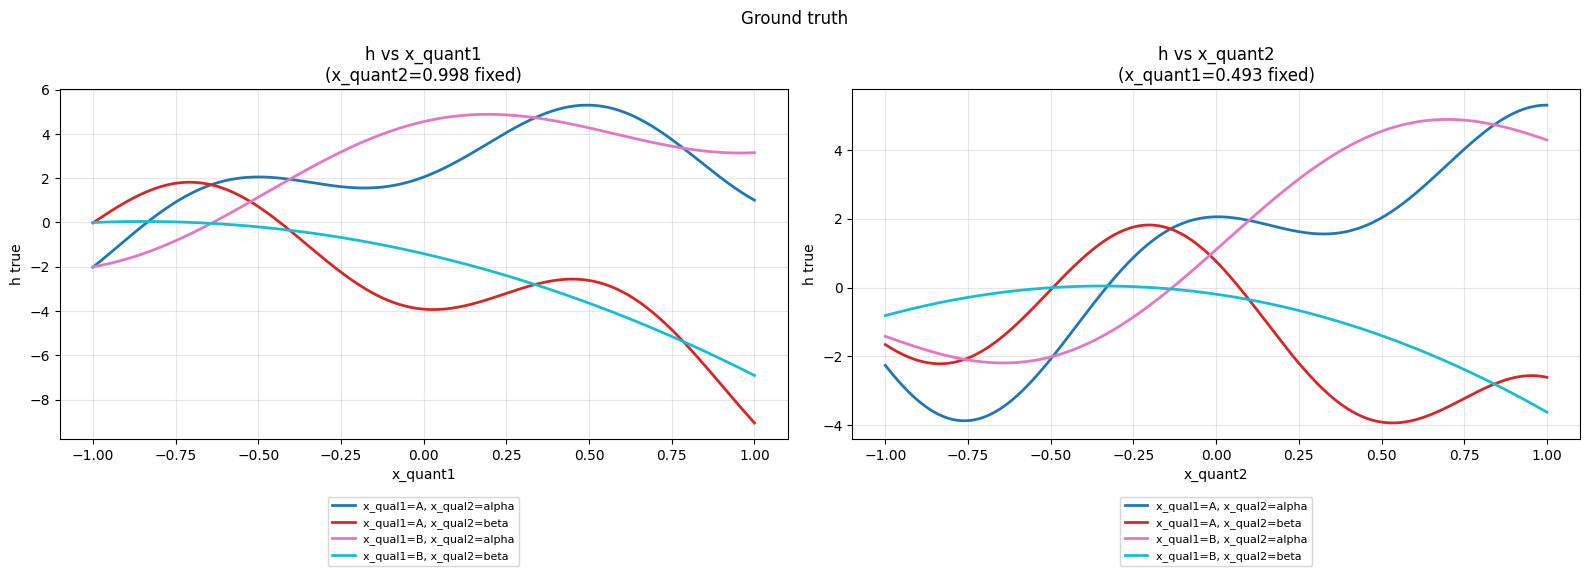

In [7]:
# plot true max 2d
plot_ground_truth(
    fn_gp_objective=case.fn_gp_objective,
    vars_metadata=case.vars_metadata,
    z=case.z,
    quant_fixed_vals=(
        (2, x_true_max[2]), 
        (3, x_true_max[3]),
        #(4, x_true_max[4])
    ),
    n_points=300,
    figsize=(8,6)
)

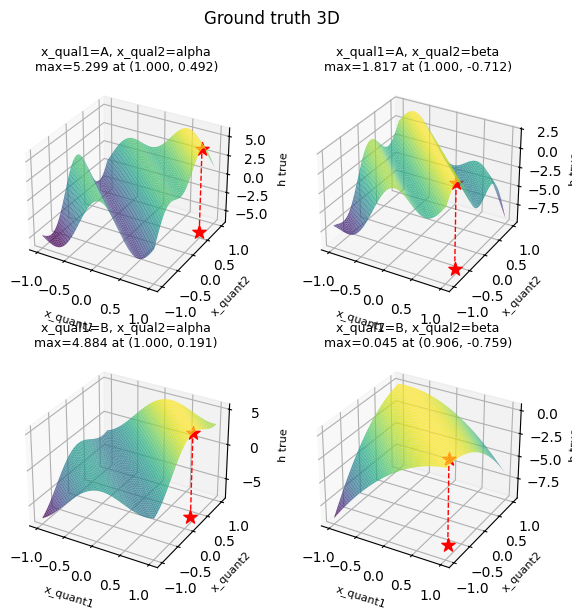

In [8]:
# plot true max 3d
plot_3d_ground_truth(
    fn_gp_objective=case.fn_gp_objective,
    vars_metadata=case.vars_metadata,
    z=case.z,
    quant_idx_1=2,
    quant_idx_2=3,
    n_points=300,
    n_cols=2,
    figsize=(3,3)    
)

In [11]:
# EGO
design_space = XprSmt.create_design_space(
    vars_metadata=case.vars_metadata,
    sampling_method=sampling_method,
    sampling_criterion=sampling_criterion,
    seed=seed
)

x_init = XprSmt.calc_x_init_with_sampling_method(
    n_init=n_init,
    design_space=design_space,
    sampling_method=sampling_method,
    sampling_criterion=sampling_criterion,
    seed=seed
)

y_init = XprSmt.calc_y_objective_for_ego(
    fn_gp_objective=case.fn_gp_objective,
    vars_metadata=case.vars_metadata,
    x=x_init, 
    z=case.z,
    sigma_noise=sigma_noise, 
    rng=np.random.default_rng(seed+seed_ydoe_offset)
)

res_ego = XprSmt.run_ego(
    fn_gp_objective=case.fn_gp_objective,
    vars_metadata=case.vars_metadata,
    design_space=design_space,
    x_init=x_init,
    y_init=y_init,
    z=case.z,
    n_iter_bo=n_iter_bo,
    kernel=kernel,
    bo_criterion=bo_criterion,
    qei=qei,
    sigma_noise=sigma_noise,
    n_start=n_start,
    seed=seed
)

In [18]:
# EGO results details
print(f"--- BO x_data ---\n{res_ego.x_data}")
print(f"\n--- BO y_data ---\n{res_ego.y_data}")

print("\n--- Results ---")
XprSmt.print_opt_result(x=res_ego.x_opt, y=res_ego.y_true_at_x_opt, vars_metadata=case.vars_metadata)

--- BO x_data ---
[[ 0.          1.          0.46824977  0.86018371]
 [ 0.          0.          0.87421679 -0.63489777]
 [ 1.          1.         -0.27365858  0.01658449]
 [ 1.          0.         -0.6746919   0.4588758 ]
 [ 0.          1.          0.14527157 -0.5989046 ]
 [ 0.          1.         -0.98319622 -0.08058253]
 [ 1.          0.          0.5491328   0.17673736]
 [ 1.          0.          0.33685949 -0.67472843]
 [ 1.          0.          0.63239292  0.04677647]
 [ 0.          0.          0.79301894  0.21272898]
 [ 1.          0.          0.54141975  0.38887024]
 [ 1.          0.          0.52613842  0.72897142]
 [ 1.          0.          0.68780153  0.7788487 ]
 [ 1.          0.          0.4537516   0.86752131]
 [ 0.          0.          0.49879829  0.82482565]]

--- BO y_data ---
[[-2.85896127]
 [ 0.78536924]
 [-0.11810774]
 [-1.95913946]
 [-1.92911666]
 [-0.60738675]
 [ 3.00780242]
 [-1.87133136]
 [ 2.67068793]
 [ 2.04173205]
 [ 4.31910855]
 [ 4.98340825]
 [ 4.47004886]
 [

In [13]:
# check repartition qualitative variables
for q1 in range(len(case.vars_metadata[0].support)): 
    for q2 in range(len(case.vars_metadata[1].support)): 
        mask = (res_ego.x_data[:n_init,0]==q1) & (res_ego.x_data[:n_init,1]==q2)
        print(f"qual1={q1} qual2={q2}: {mask.sum()} points")

qual1=0 qual2=0: 1 points
qual1=0 qual2=1: 2 points
qual1=1 qual2=0: 1 points
qual1=1 qual2=1: 1 points


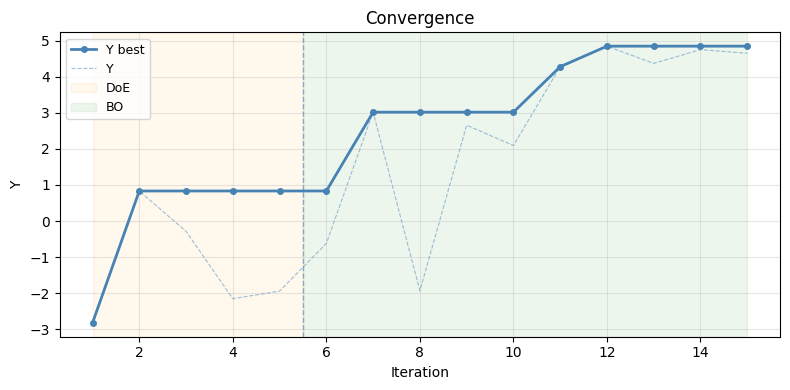

In [14]:
# plot convergence
plot_convergence(
    y_data=res_ego.y_true_at_x_data,
    n_init=n_init,
)

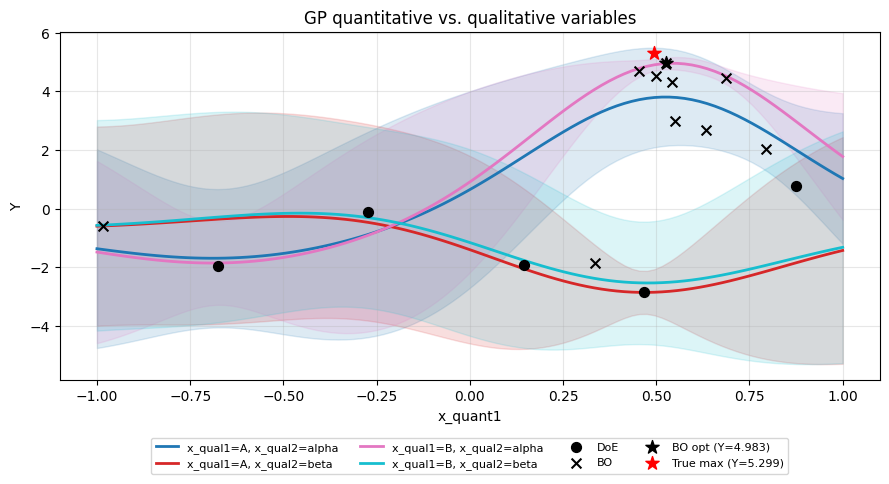

In [ ]:
# plot GP quant1 by qual
plot_gp_quant_by_qual(
    sm=res_ego.sm,
    vars_metadata=case.vars_metadata,
    x_opt=res_ego.x_opt,
    quant_to_variate_idx=2,
    reverse_optim=True,
    qual_filter=[(0, ["A", "B"]), (1, ["alpha", "beta"])],
    x_data=res_ego.x_data,
    y_data=res_ego.y_data,
    n_init=n_init,
    y_opt=res_ego.y_opt,
    x_true_max=x_true_max,
    y_true_max=y_true_max,
    figsize=(9,5)
)

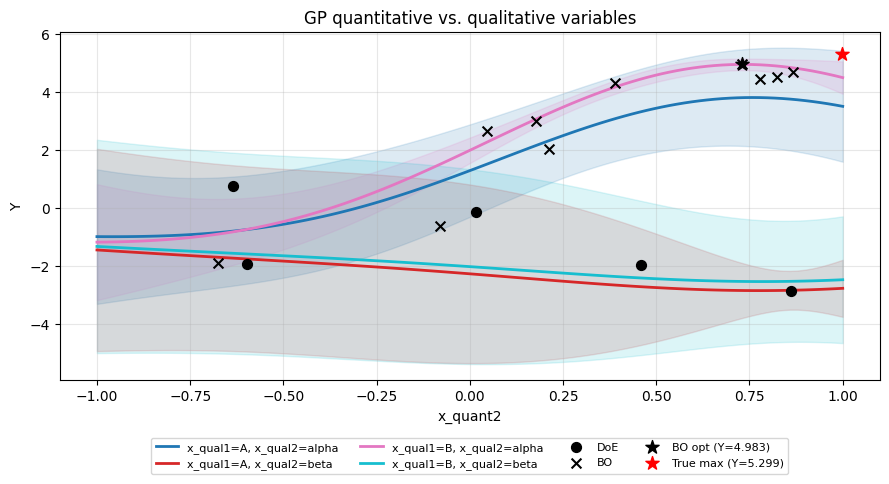

In [ ]:
# plot GP quant2 by qual
plot_gp_quant_by_qual(
    sm=res_ego.sm,
    vars_metadata=case.vars_metadata,
    x_opt=res_ego.x_opt,
    quant_to_variate_idx=3,
    reverse_optim=True,
    qual_filter=[(0, ["A", "B"]), (1, ["alpha", "beta"])],
    x_data=res_ego.x_data,
    y_data=res_ego.y_data,
    n_init=n_init,
    y_opt=res_ego.y_opt,
    x_true_max=x_true_max,
    y_true_max=y_true_max,
    figsize=(9,5)    
)

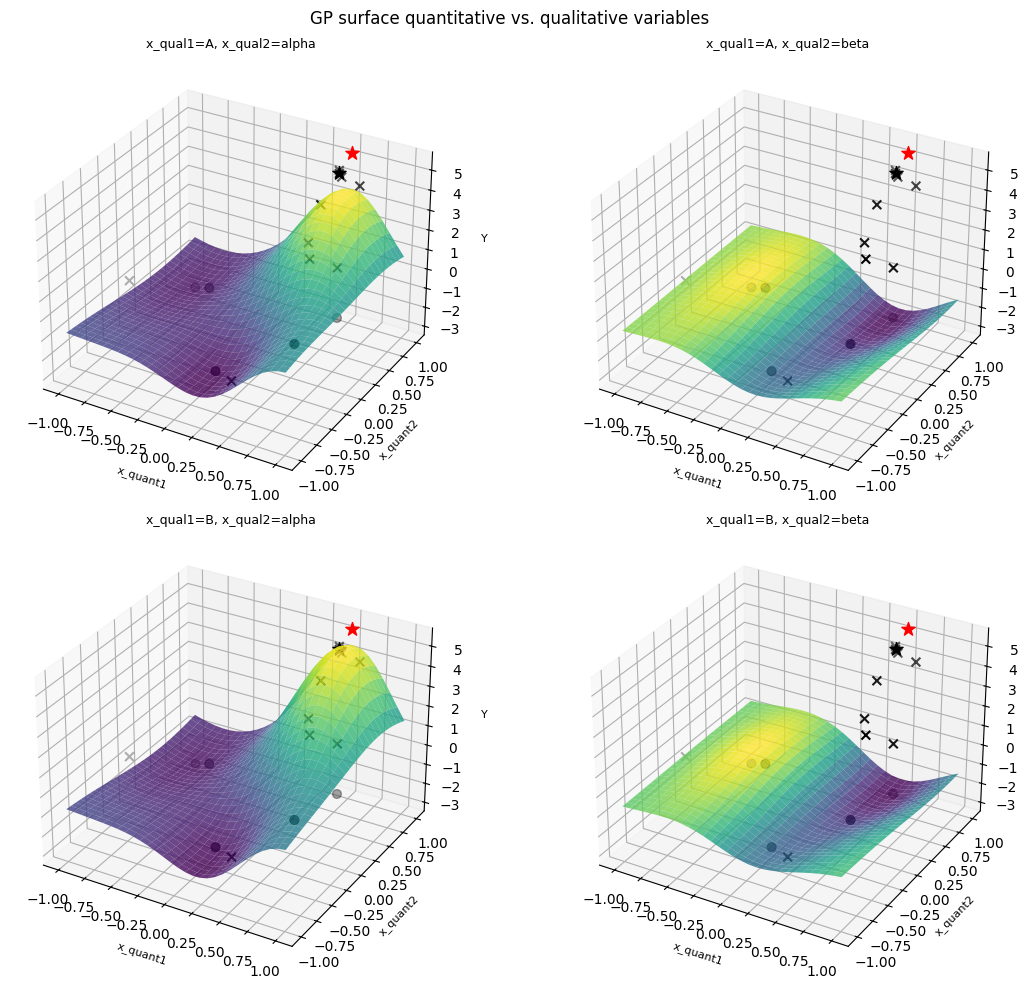

In [17]:
# plot GP 3d
plot_3d_gp_quant_by_qual(
    sm=res_ego.sm,
    vars_metadata=case.vars_metadata,
    x_opt=res_ego.x_opt,
    quant_to_variate_idx_1=2,
    quant_to_variate_idx_2=3,
    reverse_optim=True,
    qual_filter=None,
    x_data=res_ego.x_data,
    y_data=res_ego.y_data,
    n_init=n_init,
    y_opt=res_ego.y_opt,
    x_true_max=x_true_max,
    y_true_max=y_true_max,
    n_cols=2
)